### (2) 합성곱 신경망 맛보기

[합성곱 신경망 구현 (fashion_mnist 데이터셋)]

In [1]:
# 라이브러리 호출
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.autograd import Variable
import torch.nn.functional as F

import torchvision
import torchvision.transforms as transforms # 데이터 전처리를 위해 사용하는 라이브러리
from torch.utils.data import Dataset, DataLoader

In [2]:
# CPU 혹은 GPU 장치 확인
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

[GPU 사용]

In [4]:
'''
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = Net()
model.to(device)
'''

'\ndevice = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")\nmodel = Net()\nmodel.to(device)\n'

In [5]:
'''
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = Net()
if torch.cuda.device_count() > 1:
    model = nn.DataParallel(model)
model.to(device)
'''

'\ndevice = torch.device("cuda" if torch.cuda.is_available() else "cpu")\nmodel = Net()\nif torch.cuda.device_count() > 1:\n    model = nn.DataParallel(model)\nmodel.to(device)\n'

In [6]:
# fashion_mnist 데이터셋 내려받기
train_dataset = torchvision.datasets.FashionMNIST("../chap05/data", download=True,
    transform=transforms.Compose([transforms.ToTensor()]))

test_dataset = torchvision.datasets.FashionMNIST("../chap05/data", download=True,
    train=False, transform=transforms.Compose([transforms.ToTensor()]))

100%|██████████| 26.4M/26.4M [00:01<00:00, 19.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 306kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.64MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 24.7MB/s]


In [7]:
# fashion_mnist 데이터를 데이터로더에 전달
train_loader = torch.utils.data.DataLoader(train_dataset,
                                           batch_size=100)
test_loader = torch.utils.data.DataLoader(test_dataset,
                                          batch_size=100)

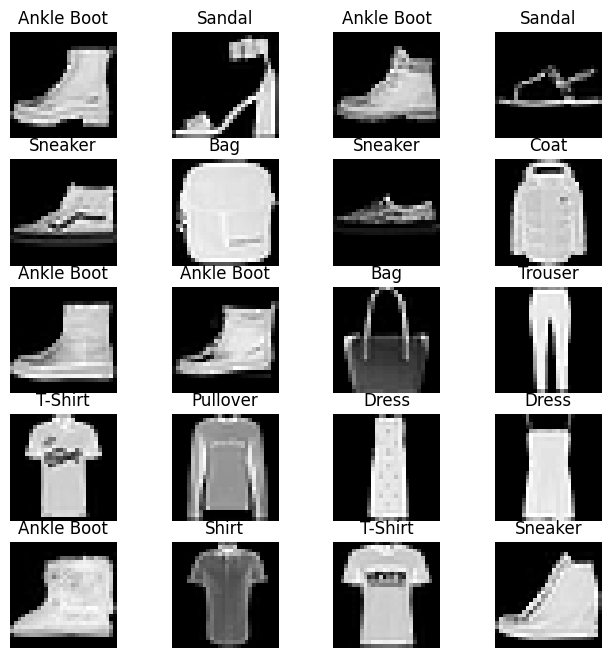

In [8]:
# 분류에 사용될 클래스 정의
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot"
} #열 개의 클래스

fig = plt.figure(figsize=(8, 8))
columns = 4
rows = 5
for i in range(1, columns * rows + 1):
    img_xy = np.random.randint(len(train_dataset))
    img = train_dataset[img_xy][0].squeeze()
    fig.add_subplot(rows, columns, i)
    plt.title(labels_map[train_dataset[img_xy][1]])
    plt.axis("off")
    plt.imshow(img, cmap="gray")
plt.show() #20개의 이미지 데이터를 시각적으로 표현

In [11]:
# random.rand와 random.randn 예시
'''
import numpy as np
np.random.randint(10)

np.random.randint(1, 10)

np.random.rand(8)

np.random.rand(4, 2)

np.random.randn(8)

np.random.randn(4, 2)
'''

'\nimport numpy as np\nnp.random.randint(10)\n\nnp.random.randint(1, 10)\n\nnp.random.rand(8)\n\nnp.random.rand(4, 2)\n\nnp.random.randn(8)\n\nnp.random.randn(4, 2)\n'

In [10]:
#train_dataset을 이용한 3차원 배열 생성
'''
import numpy as np
examp = np.arange(0, 100, 3)
examp.resize(6, 4)
examp

examp[3]

examp[3, 3]

examp[3][3]

examp = np.arange(0, 500, 3)
examp.resize(3, 5, 5)
examp

examp[2][0][3]
'''

'\nimport numpy as np\nexamp = np.arange(0, 100, 3)\nexamp.resize(6, 4)\nexamp\n\nexamp[3]\n\nexamp[3, 3]\n\nexamp[3][3]\n\nexamp = np.arange(0, 500, 3)\nexamp.resize(3, 5, 5)\nexamp\n\nexamp[2][0][3]\n'

In [21]:
# 심층 신경망 모델 생성
class FashionDNN(nn.Module):
    def __init__(self):
        super(FashionDNN, self).__init__()

        self.fc1 = nn.Linear(in_features=784, out_features=256)
        self.drop = nn.Dropout2d(0.25)
        self.fc2 = nn.Linear(in_features=256, out_features=128)
        self.fc3 = nn.Linear(in_features=128, out_features=10)

    def forward(self, input_data):
        out = input_data.view(-1, 784)
        out = F.relu(self.fc1(out))
        out = self.drop(out)
        out = F.relu(self.fc2(out))
        out = self.fc3(out)

        return out

[객체]

- 객체 지향 프로그래밍: 데이터와 기능을 객체로 만들어 서로 상호작용하도록 하는 프로그래밍 방식
- 클래스(Class): 객체를 만들기 위한 설계도 (붕어빵 틀)
- 객체(Object): 클래스를 통해 만들어진 실체 (붕어빵)
- 장점: 코드의 재사용성이 높음
- 파이썬에서는 변수, 함수 등도 모두 객체에 해당함.

[클래스와 함수]
- 함수: 특정 작업을 수행하는 독립적인 코드. 결과값을 계속 사용하려면 별도로 저장해야 함.
- 클래스: 함수뿐만 아니라 관련 변수(데이터)까지 하나로 묶어 관리하고 재사용할 수 있게 해주는 것.

In [13]:
# 함수에 대한 예시
'''
def add(num1, num2):
  result = num1 + num2
  return result

print(add(1, 2))
print(add(2, 3))
'''

'\ndef add(num1, num2):\n  result = num1 + num2\n  return result\n\nprint(add(1, 2))\nprint(add(2, 3))\n'

In [15]:
# 클래스에 대한 예시
'''
class Calc:
  def __init__(self):
    self.result = 0

  def add(self, num1, num2):
    self.result = num1 + num2
    return self.result

obj1 = Calc()
obj2 = Calc()

print(obj1.add(1, 2))
print(obj1.add(2, 3))
print('--------------------')
print(obj2.add(2, 2))
print(obj2.add(2, 3))
'''

"\nclass Calc:\n  def __init__(self):\n    self.result = 0\n\n  def add(self, num1, num2):\n    self.result = num1 + num2\n    return self.result\n\nobj1 = Calc()\nobj2 = Calc()\n\nprint(obj1.add(1, 2))\nprint(obj1.add(2, 3))\nprint('--------------------')\nprint(obj2.add(2, 2))\nprint(obj2.add(2, 3))\n"

In [16]:
# nn을 사용하는 코드
'''
import torch
import torch.nn as nn

inputs = torch.randn(64, 3, 244, 244)
conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
outputs = conv(inputs)
layer = nn.Conv2d(1, 1, 3)
'''

'\nimport torch\nimport torch.nn as nn\n\ninputs = torch.randn(64, 3, 244, 244)\nconv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)\noutputs = conv(inputs)\nlayer = nn.Conv2d(1, 1, 3)\n'

In [17]:
# nn.functional을 사용하는 코드
'''
import torch.nn.functional as F

inputs = torch.randn(64, 3, 244, 244)
weight = torch.randn(64, 3, 3, 3)
bias = torch.randn(64)
outputs = F.conv2d(inputs, weight, bias, padding=1)
'''

'\nimport torch.nn.functional as F\n\ninputs = torch.randn(64, 3, 244, 244)\nweight = torch.randn(64, 3, 3, 3)\nbias = torch.randn(64)\noutputs = F.conv2d(inputs, weight, bias, padding=1)\n'

[사용 방법 비교]
| 구분 | nn.xx | nn.functional.xx |
|---|---|---|
| 형태 | nn.Conv2d: 클래스<br>nn.Module을 상속받아 사용 | nn.functional.conv2d: 함수<br>순수 함수로 정의 |
| 호출 방법 | 하이퍼파라미터를 먼저 전달한 후 데이터 전달 | 함수 호출 시 하이퍼파라미터와 데이터 전달 |
| 위치 | nn.Sequential 내에 위치 가능 | nn.Sequential 내에 위치 불가 |
| 파라미터 | 파라미터를 새로 정의할 필요 없음 | 가중치를 직접 정의하고 전달해야 함 |

In [22]:
# 심층 신경망에서 필요한 파라미터 정의
learning_rate = 0.001
model = FashionDNN()
model.to(device)

criterion = nn.CrossEntropyLoss()  # 분류 문제에서 사용하는 손실 함수
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
print(model)

FashionDNN(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (drop): Dropout2d(p=0.25, inplace=False)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
)


In [23]:
# 심층 신경망을 이용한 모델 학습
num_epochs = 5
count = 0

loss_list = []
iteration_list = []
accuracy_list = []

predictions_list = []
labels_list = []

for epoch in range(num_epochs):
  for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)

    train = Variable(images.view(100, 1, 28, 28))
    labels = Variable(labels)

    outputs = model(train)
    loss = criterion(outputs, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    count += 1

    if not (count % 50):
      total = 0
      correct = 0
      for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        labels_list.append(labels)
        test = Variable(images.view(100, 1, 28, 28))
        outputs = model(test)
        predictions = torch.max(outputs, 1)[1].to(device)
        predictions_list.append(predictions)
        correct += (predictions == labels).sum()
        total += len(labels)

      accuracy = correct * 100 / total
      loss_list.append(loss.data)
      iteration_list.append(count)
      accuracy_list.append(accuracy)

    if not (count % 500):
      print("Iteration: {}, Loss: {}, Accuracy: {}%".format(count, loss.data, accuracy))

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/dropout.py:176: UserWarning: dropout2d: Received a 2-D input to dropout2d, which is deprecated and will result in an error in a future release. To retain the behavior and silence this warning, please use dropout instead. Note that dropout2d exists to provide channel-wise dropout on inputs with 2 spatial dimensions, a channel dimension, and an optional batch dimension (i.e. 3D or 4D inputs).
  return F.dropout2d(input, self.p, self.training, self.inplace)


Iteration: 500, Loss: 0.5467346906661987, Accuracy: 83.5%
Iteration: 1000, Loss: 0.46192222833633423, Accuracy: 84.5199966430664%
Iteration: 1500, Loss: 0.3952571153640747, Accuracy: 83.75999450683594%
Iteration: 2000, Loss: 0.35261067748069763, Accuracy: 86.02999877929688%
Iteration: 2500, Loss: 0.24847495555877686, Accuracy: 86.58999633789062%
Iteration: 3000, Loss: 0.34280478954315186, Accuracy: 86.5199966430664%


[심층 신경망 학습]
1. 리스트(List)
- 빈 리스트 []를 생성한 후 append()를 이용해 데이터를 하나씩 추가할 수 있음.

2. for in 구문
- 데이터를 하나씩 가져와 반복 처리하는 구문.
- for x, y in train:은 각 레코드에서 두 개의 요소를 가져온다는 의미.

3. 데이터와 모델의 장치 일치
- 모델과 데이터는 동일한 장치(CPU 또는 GPU)에서 처리해야 함.
- model.to(device)와 images.to(device), labels.to(device)를 동일하게 설정.
- 서로 다른 장치에서 연산하면 런타임 오류 발생.

4. Autograd (자동 미분)
- 파이토치에서 자동으로 미분값을 계산하는 기능.
- 순전파 과정에서 연산을 기록하고, 역전파 과정에서 이를 이용해 기울기를 계산함.
- 현재는 Variable 없이도 Tensor의 자동 미분 기능을 사용할 수 있음.

5. 분류 정확도(Classification Accuracy)
- 전체 예측 중 정답을 맞힌 비율.
- 정확도(Accuracy)와 오분류율(Error Rate)은 서로 반대 개념.
$$
Accuracy = \frac{Correct\ Predictions}{Total\ Predictions} \times 100
$$

$$
Error\ Rate = \left(1 - \frac{Correct\ Predictions}{Total\ Predictions}\right) \times 100
$$

6. 다중 클래스 분류에서 정확도의 한계
- 전체 정확도만으로는 클래스별 분류 성능을 알기 어려움.
- 특정 클래스에 데이터가 몰려 있는 불균형 데이터에서는 정확도가 높아도 실제 성능이 낮을 수 있음.

In [24]:
# 합성곱 네트워크 생성
class FashionCNN(nn.Module):
    def __init__(self):
        super(FashionCNN, self).__init__()
        self.layer1 = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.layer2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.fc1 = nn.Linear(in_features=64*6*6, out_features=600)
        self.drop = nn.Dropout2d(0.25)
        self.fc2 = nn.Linear(in_features=600, out_features=120)
        self.fc3 = nn.Linear(in_features=120, out_features=10)

    def forward(self, x):
        out = self.layer1(x)
        out = self.layer2(out)
        out = out.view(out.size(0), -1)
        out = self.fc1(out)
        out = self.drop(out)
        out = self.fc2(out)
        out = self.fc3(out)
        return out

[CNN(합성곱 신경망)]
1. nn.Sequential
- 여러 개의 신경망 계층을 하나의 컨테이너에 순서대로 쌓는 방법.
- __init__()에서 계층을 정의하고 순서대로 연결하여 가독성을 높임.
- 데이터가 각 계층을 순차적으로 통과할 때 사용.
2. 합성곱층(Convolution Layer)
- 이미지에서 특징(Feature)을 추출하는 계층.
- 커널(Filter)이 이미지를 이동하면서 각 원소를 곱하고 모두 더해 새로운 값을 생성함.
- 일반적으로 3×3, 5×5 크기의 커널 사용.
3. nn.Conv2d() 주요 파라미터
| 파라미터 | 의미 |
|---|---|
| `in_channels` | 입력 채널 수 |
| `out_channels` | 출력 채널 수 (필터 개수) |
| `kernel_size` | 커널(필터) 크기 |
| `padding` | 이미지 가장자리에 추가하는 값 |
4. 채널(Channel)이란?
- 이미지의 색상 정보를 구성하는 데이터의 깊이(Depth).
- 흑백 이미지: 1개 채널
- 컬러 이미지(RGB): 3개 채널 (Red, Green, Blue)
| 이미지 종류 | 형태 | 채널 수 |
|---|---|---|
| 흑백 이미지 | W × H × 1 | 1 |
| 컬러 이미지 (RGB) | W × H × 3 | 3 |
5. out_channels
- 출력 채널의 수를 의미함.
- 즉, 합성곱에 사용되는 필터의 개수와 같음.
6. kernel_size (커널 크기)
- 이미지의 특징을 추출하기 위한 필터의 크기.
- CNN에서 학습되는 주요 파라미터는 커널(필터)의 가중치임.
- 커널은 스트라이드(Stride) 간격으로 이동하며 합성곱 연산을 수행함.
- kernel_size=3 → 3×3 정사각형
- kernel_size=(3, 5) → 3×5 직사각형
7. padding (패딩)
- 출력 크기를 조정하기 위해 입력 데이터 주변에 값을 추가하는 것.
- 일반적으로 0을 추가하는 Zero Padding 사용.
- 패딩이 커질수록 출력 크기도 커짐.
8. BatchNorm2d (배치 정규화)
- 각 배치의 데이터 분포를 정규화하는 기법.
- 평균과 분산을 이용해 데이터 분포를 조정함.
- 학습 과정의 안정성과 수렴에 도움을 줌.
- 정규화 과정에서 평균 0, 분산 1을 기준으로 조정함. (정확히는 정규화 직후 기준이며, 이후 학습 가능한 파라미터로 변환될 수 있음.)
9. Max Pooling (최대 풀링)
- 이미지의 크기를 줄이는 역할을 하는 계층
- 합성곱층의 출력 데이터를 입력받아 주요 특징을 추출하면서 크기를 축소함
- 대표적인 풀링 방법
  - 최대 풀링(Max Pooling): 영역 내 최댓값 선택
  - 평균 풀링(Average Pooling): 영역 내 평균값 선택
  - 최소 풀링(Min Pooling): 영역 내 최솟값 선택

10. 출력 크기(Output Size)
- Conv2d와 MaxPool2d를 거치면 이미지의 가로·세로 크기가 달라짐.
- 출력 크기는 커널 크기, 패딩, 스트라이드 등에 따라 결정됨.
- 이렇게 줄어든 출력 데이터는 최종적으로 분류를 담당하는 완전연결층(FC Layer)으로 전달됨.

11. 완전연결층 (Fully Connected Layer)
- in_features: 입력 데이터의 크기
- out_features: 출력 뉴런의 개수
- CNN에서 추출한 이미지 데이터는 3차원 형태(채널, 높이, 너비)이므로, 완전연결층에 전달하기 전에 1차원으로 펼쳐야 함(Flatten).



[Conv2d 계층에서의 출력 크기]

- 출력 크기 = \((W-K+2P)/S+1\)
- W: 입력 크기, K: 커널 크기, P: 패딩 크기, S: 스트라이드

[MaxPool2d 계층에서의 출력 크기]
- 출력 크기 = 입력 크기(IF) / 커널 크기(F)


[Flatten (1차원 변환)]
- 합성곱층에서 완전연결층(Linear)으로 넘어가기 위해 텐서의 형태를 1차원으로 변환

In [25]:
# 합성곱 네트워크를 위한 파라미터 정의
learning_rate = 0.001;
model = FashionCNN();
model.to(device)

criterion = nn.CrossEntropyLoss();
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate);
print(model)

FashionCNN(
  (layer1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (layer2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc1): Linear(in_features=2304, out_features=600, bias=True)
  (drop): Dropout2d(p=0.25, inplace=False)
  (fc2): Linear(in_features=600, out_features=120, bias=True)
  (fc3): Linear(in_features=120, out_features=10, bias=True)
)


In [26]:
# 모델 학습 및 성능 평가
num_epochs = 5
count = 0
loss_list = []
iteration_list = []
accuracy_list = []

predictions_list = []
labels_list = []

for epoch in range(num_epochs):
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        train = Variable(images.view(100, 1, 28, 28))
        labels = Variable(labels)

        outputs = model(train)
        loss = criterion(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        count += 1

        if not (count % 50):
          total = 0
          correct = 0
          for images, labels in test_loader:
              images, labels = images.to(device), labels.to(device)
              labels_list.append(labels)
              test = Variable(images.view(100, 1, 28, 28))
              outputs = model(test)
              predictions = torch.max(outputs, 1)[1].to(device)
              predictions_list.append(predictions)
              correct += (predictions == labels).sum()
              total += len(labels)

          accuracy = correct * 100 / total
          loss_list.append(loss.data)
          iteration_list.append(count)
          accuracy_list.append(accuracy)

        if not (count % 500):
          print("Iteration: {}, Loss: {}, Accuracy: {}%".format(count, loss.data, accuracy))

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/dropout.py:176: UserWarning: dropout2d: Received a 2-D input to dropout2d, which is deprecated and will result in an error in a future release. To retain the behavior and silence this warning, please use dropout instead. Note that dropout2d exists to provide channel-wise dropout on inputs with 2 spatial dimensions, a channel dimension, and an optional batch dimension (i.e. 3D or 4D inputs).
  return F.dropout2d(input, self.p, self.training, self.inplace)


Iteration: 500, Loss: 0.43963006138801575, Accuracy: 87.4000015258789%
Iteration: 1000, Loss: 0.27642735838890076, Accuracy: 88.72000122070312%
Iteration: 1500, Loss: 0.33171844482421875, Accuracy: 87.0999984741211%
Iteration: 2000, Loss: 0.22565323114395142, Accuracy: 89.31999969482422%
Iteration: 2500, Loss: 0.126801535487175, Accuracy: 89.3699951171875%
Iteration: 3000, Loss: 0.17124037444591522, Accuracy: 89.30999755859375%
